<a href="https://colab.research.google.com/github/26005165/data-science-toolkit/blob/main/Tutorial3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
# 1. Find some real dataset. Load it on Colab, Kaggle etc. Try to visualize some of it
# I used the meteorite landing dataset as my dataset to visualize in this tuto exercise.
import pandas as pd

df = pd.read_csv("/content/drive/MyDrive/meteorite-landings.csv")

display(df.head())

,name,id,nametype,recclass,mass,fall,year,reclat,reclong,GeoLocation
0,Aachen,1,Valid,L5,21.0,Fell,1880.0,50.77500,6.08333,"(50.775000, 6.083330)"
1,Aarhus,2,Valid,H6,720.0,Fell,1951.0,56.18333,10.23333,"(56.183330, 10.233330)"
2,Abee,6,Valid,EH4,107000.0,Fell,1952.0,54.21667,-113.00000,"(54.216670, -113.000000)"
3,Acapulco,10,Valid,Acapulcoite,1914.0,Fell,1976.0,16.88333,-99.90000,"(16.883330, -99.900000)"
4,Achiras,370,Valid,L6,780.0,Fell,1902.0,-33.16667,-64.95000,"(-33.166670, -64.950000)"


In [8]:
# 2. Evaluate if the data is good or not. Does it have enough samples?
print("Number of rows and columns", df.shape)
print("Repeated id of meteorite: ", df["id"].duplicated().sum())
print("Fall condition (Fell/Found): ")
print(df["fall"].value_counts())

Number of rows and columns (45716, 10)
Repeated id of meteorite:  0
Fall condition (Fell/Found): 
fall
Found    44609
Fell      1107
Name: count, dtype: int64


In [10]:
# 3. How many features does it have? Is it enough?
print("Columns: ")
print(df.columns.tolist())
print("Total number of columns: ", len(df.columns))
print("Total number of features (Excluding fall): ", len(df.columns)-1)



Columns: 
['name', 'id', 'nametype', 'recclass', 'mass', 'fall', 'year', 'reclat', 'reclong', 'GeoLocation']
Total number of columns:  10
Total number of features (Excluding fall):  9


In [11]:
# 4. How many samples/observation does it have? Is it enough?
print("Number of meteorite: ", len(df))

Number of samples:  434796


In [14]:
# 5. What are the datatypes does the dataset consist of?
print(df.dtypes)

# This dataset consists of object, int64, float64.
# object represents String
# int64 represents integer
# float64 represents decimal numbers


name            object
id               int64
nametype        object
recclass        object
mass           float64
fall            object
year           float64
reclat         float64
reclong        float64
GeoLocation     object
dtype: object


In [21]:
# 6. How many columns have null values? If yes, which column, which rows
null = df.isnull().sum()
print("Number of columns with null values: ", (null > 0).sum())
print("\nColumns and rows with null values: ")
print(null[null > 0])





Number of columns with null values:  5

Columns and rows with null values: 
mass            131
year            288
reclat         7315
reclong        7315
GeoLocation    7315
dtype: int64


In [32]:
# 7. Which column is the feature, which is the target output?
target = "fall"
features = df.drop(columns = ["fall","id"])


print("Features: ")
print(features.columns.tolist())

print("\nTarget Output (fall column): ")
print(df[target].unique())

Features: 
['name', 'nametype', 'recclass', 'mass', 'year', 'reclat', 'reclong', 'GeoLocation']

Target Output (fall column): 
['Fell' 'Found']


In [5]:
# 8. Does it have missing values? If yes, which column, which row.


# Check whether the dataset has any missing values
if df.isnull().values.any():
    print("Yes, the dataset contains missing values.")

    # Identify the columns and rows with missing values
    for col in df.columns:
        missing_rows = df.index[df[col].isnull()].tolist()

        if missing_rows:
            print(f"\nColumn: {col}")
            print(f"Missing row indices: {missing_rows}")
else:
    print("No missing values found.")


Yes, the dataset contains missing values.

Column: mass
Missing row indices: [12, 38, 76, 93, 172, 204, 262, 308, 312, 320, 324, 346, 392, 561, 577, 644, 664, 678, 692, 709, 729, 747, 751, 773, 785, 791, 865, 953, 1014, 1040, 1051, 1076, 3440, 3452, 5044, 5045, 5123, 5182, 5242, 5268, 5432, 5468, 5479, 5583, 5693, 5694, 6844, 6876, 9168, 9217, 12536, 12539, 12595, 15938, 15943, 15944, 15959, 16356, 16367, 16368, 16403, 16472, 16547, 17249, 17273, 17341, 17363, 17391, 17462, 19720, 22946, 26270, 26398, 28736, 31013, 31014, 31015, 31016, 31017, 31018, 31019, 31020, 31021, 31022, 31023, 31024, 31025, 31026, 31027, 31028, 31029, 31030, 31031, 31032, 31033, 31034, 31035, 31036, 31037, 31038, 31039, 31040, 31041, 31042, 31043, 31044, 31045, 31046, 31047, 31048, 31049, 31050, 31051, 31052, 31053, 31054, 31055, 31056, 31057, 31058, 31059, 31097, 31141, 31146, 36812, 38188, 38275, 38276, 38278, 41460, 45698]

Column: year
Missing row indices: [37, 3409, 3440, 4973, 5044, 5242, 5268, 5325, 5453,

Average meteorite mass for each group: fall
Fell     47070.72
Found    12461.92
Name: mass, dtype: float64


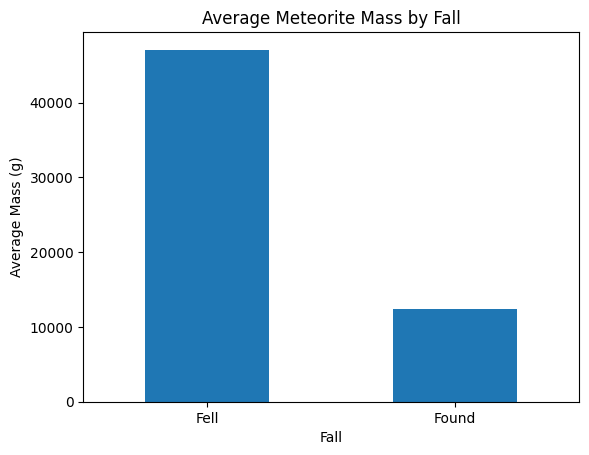

In [6]:
# 9. What kind of question can be asked, should we ask. Does the dataset suits the question we are asking?

# Quetion: Is there a relationship between meteorite mass and whether it was observed falling or discovered later?

import matplotlib.pyplot as plt

# Remove rows with missing mass and fall value
clean_df = df.dropna(subset=["mass","fall"])

# Calculate average mass for each group
average_mass = clean_df.groupby("fall")["mass"].mean()

# Print average meteorite mass
print("Average meteorite mass for each group:", average_mass.round(2))

# Create a bar chart
average_mass.plot(kind="bar")
plt.title("Average Meteorite Mass by Fall")
plt.xlabel("Fall")
plt.ylabel("Average Mass (g)")
plt.xticks(rotation=0)
plt.show()


